# 6. AIND Ephys Visualization

Build an `AINDEPhysVisualizationScanConfig`, expand it with `GridScanGenerationTask`, and run the `AINDEPhysVisualizationTask` for each coordinate. The task itself clones [aind-ephys-visualization](https://github.com/AllenNeuralDynamics/aind-ephys-visualization) on first use, seeds its `data/` with the union of dispatch + preprocessing + postprocessing + curation outputs, writes a `params_obi.json`, runs `code/run_capsule.py`, and copies the resulting figures into the single config's `coordinate_output_root` (`obi-output/06_aind_ephys_visualization/grid_scan/0/`).

Without a `KACHERY_API_KEY` (the default here) only local PNGs are emitted: drift map, raw + preprocessed trace snippets.

## Imports and prerequisites

In [1]:
import subprocess
import sys
from pathlib import Path

from obi_one.core.run_tasks import run_tasks_for_generated_scan
from obi_one.core.scan_generation import GridScanGenerationTask
from obi_one.scientific.tasks.aind_ephys._06_visualization.config import (
    AINDEPhysVisualizationScanConfig,
)

In [2]:
subprocess.run(
    [
        "uv", "pip", "install", "--python", sys.executable,
        "aind-data-schema", "sortingview", "matplotlib",
    ],
    check=True,
)

Using Python 3.12.9 environment at: /Users/james/Documents/obi/code/obi-main/obi-one/.venv
Resolved 60 packages in 8ms
Uninstalled 3 packages in 25ms
Installed 3 packages in 26ms
 - neo==0.14.3
 + neo==0.14.4
 - pydantic==2.12.5
 + pydantic==2.11.10
 - pydantic-core==2.41.5
 + pydantic-core==2.33.2


CompletedProcess(args=['uv', 'pip', 'install', '--python', '/Users/james/Documents/obi/code/obi-main/obi-one/.venv/bin/python', 'aind-data-schema', 'sortingview', 'matplotlib'], returncode=0)

## Build the scan config

Reads the dispatch, preprocessing (the 8-second one used by KS4), postprocessing, and curation outputs straight from `obi-output/`.

In [3]:
dispatch_output_path = (
    Path.cwd() / "../../../../../../obi-output/01_aind_ephys_dispatch/grid_scan/0"
).resolve()
preprocessing_output_path = (
    Path.cwd() / "../../../../../../obi-output/02_aind_ephys_preprocessing/grid_scan/0"
).resolve()
postprocessing_output_path = (
    Path.cwd() / "../../../../../../obi-output/04_aind_ephys_postprocessing/grid_scan/0"
).resolve()
curation_output_path = (
    Path.cwd() / "../../../../../../obi-output/05_aind_ephys_curation/grid_scan/0"
).resolve()

for p in (
    dispatch_output_path,
    preprocessing_output_path,
    postprocessing_output_path,
    curation_output_path,
):
    assert p.exists(), f"{p} not found. Run earlier notebooks first."

scan_config = AINDEPhysVisualizationScanConfig(
    initialize=AINDEPhysVisualizationScanConfig.Initialize(
        dispatch_output_path=dispatch_output_path,
        preprocessing_output_path=preprocessing_output_path,
        postprocessing_output_path=postprocessing_output_path,
        curation_output_path=curation_output_path,
        output_format="png",
        n_jobs=1,
    ),
)

## Generate the grid scan and run the visualization task

In [4]:
grid_scan = GridScanGenerationTask(
    form=scan_config,
    output_root="../../../../../../obi-output/06_aind_ephys_visualization/grid_scan",
    coordinate_directory_option="ZERO_INDEX",
)
grid_scan.execute()

run_tasks_for_generated_scan(grid_scan)

[2026-04-29 19:09:39,557] INFO: Seeded data dir: /tmp/aind-ephys-visualization/data


[2026-04-29 19:09:39,558] INFO: Running python -u run_capsule.py --params params_obi.json --output-format png --n-jobs 1


[2026-04-29 19:09:46,031] INFO: 

VISUALIZATION
Kachery plots disabled. KACHERY_API_KEY not found
Found 1 JSON job files
Visualizing recording: block0_None_recording1
	Found JSON file associated to recording
	Visualizing drift maps using spike sorted data
	Visualizing traces
	Visualizing sorting summary
	Skipping sorting summary visualization for block0_None_recording1. Kachery client not found.
VISUALIZATION time: 4.83s



[PosixPath('../../../obi-output/06_aind_ephys_visualization/grid_scan/0')]

## Display generated PNGs

coordinate_output_root: ../../../obi-output/06_aind_ephys_visualization/grid_scan/0
Generated 3 PNG figure(s):
  visualization_block0_None_recording1/drift_map.png


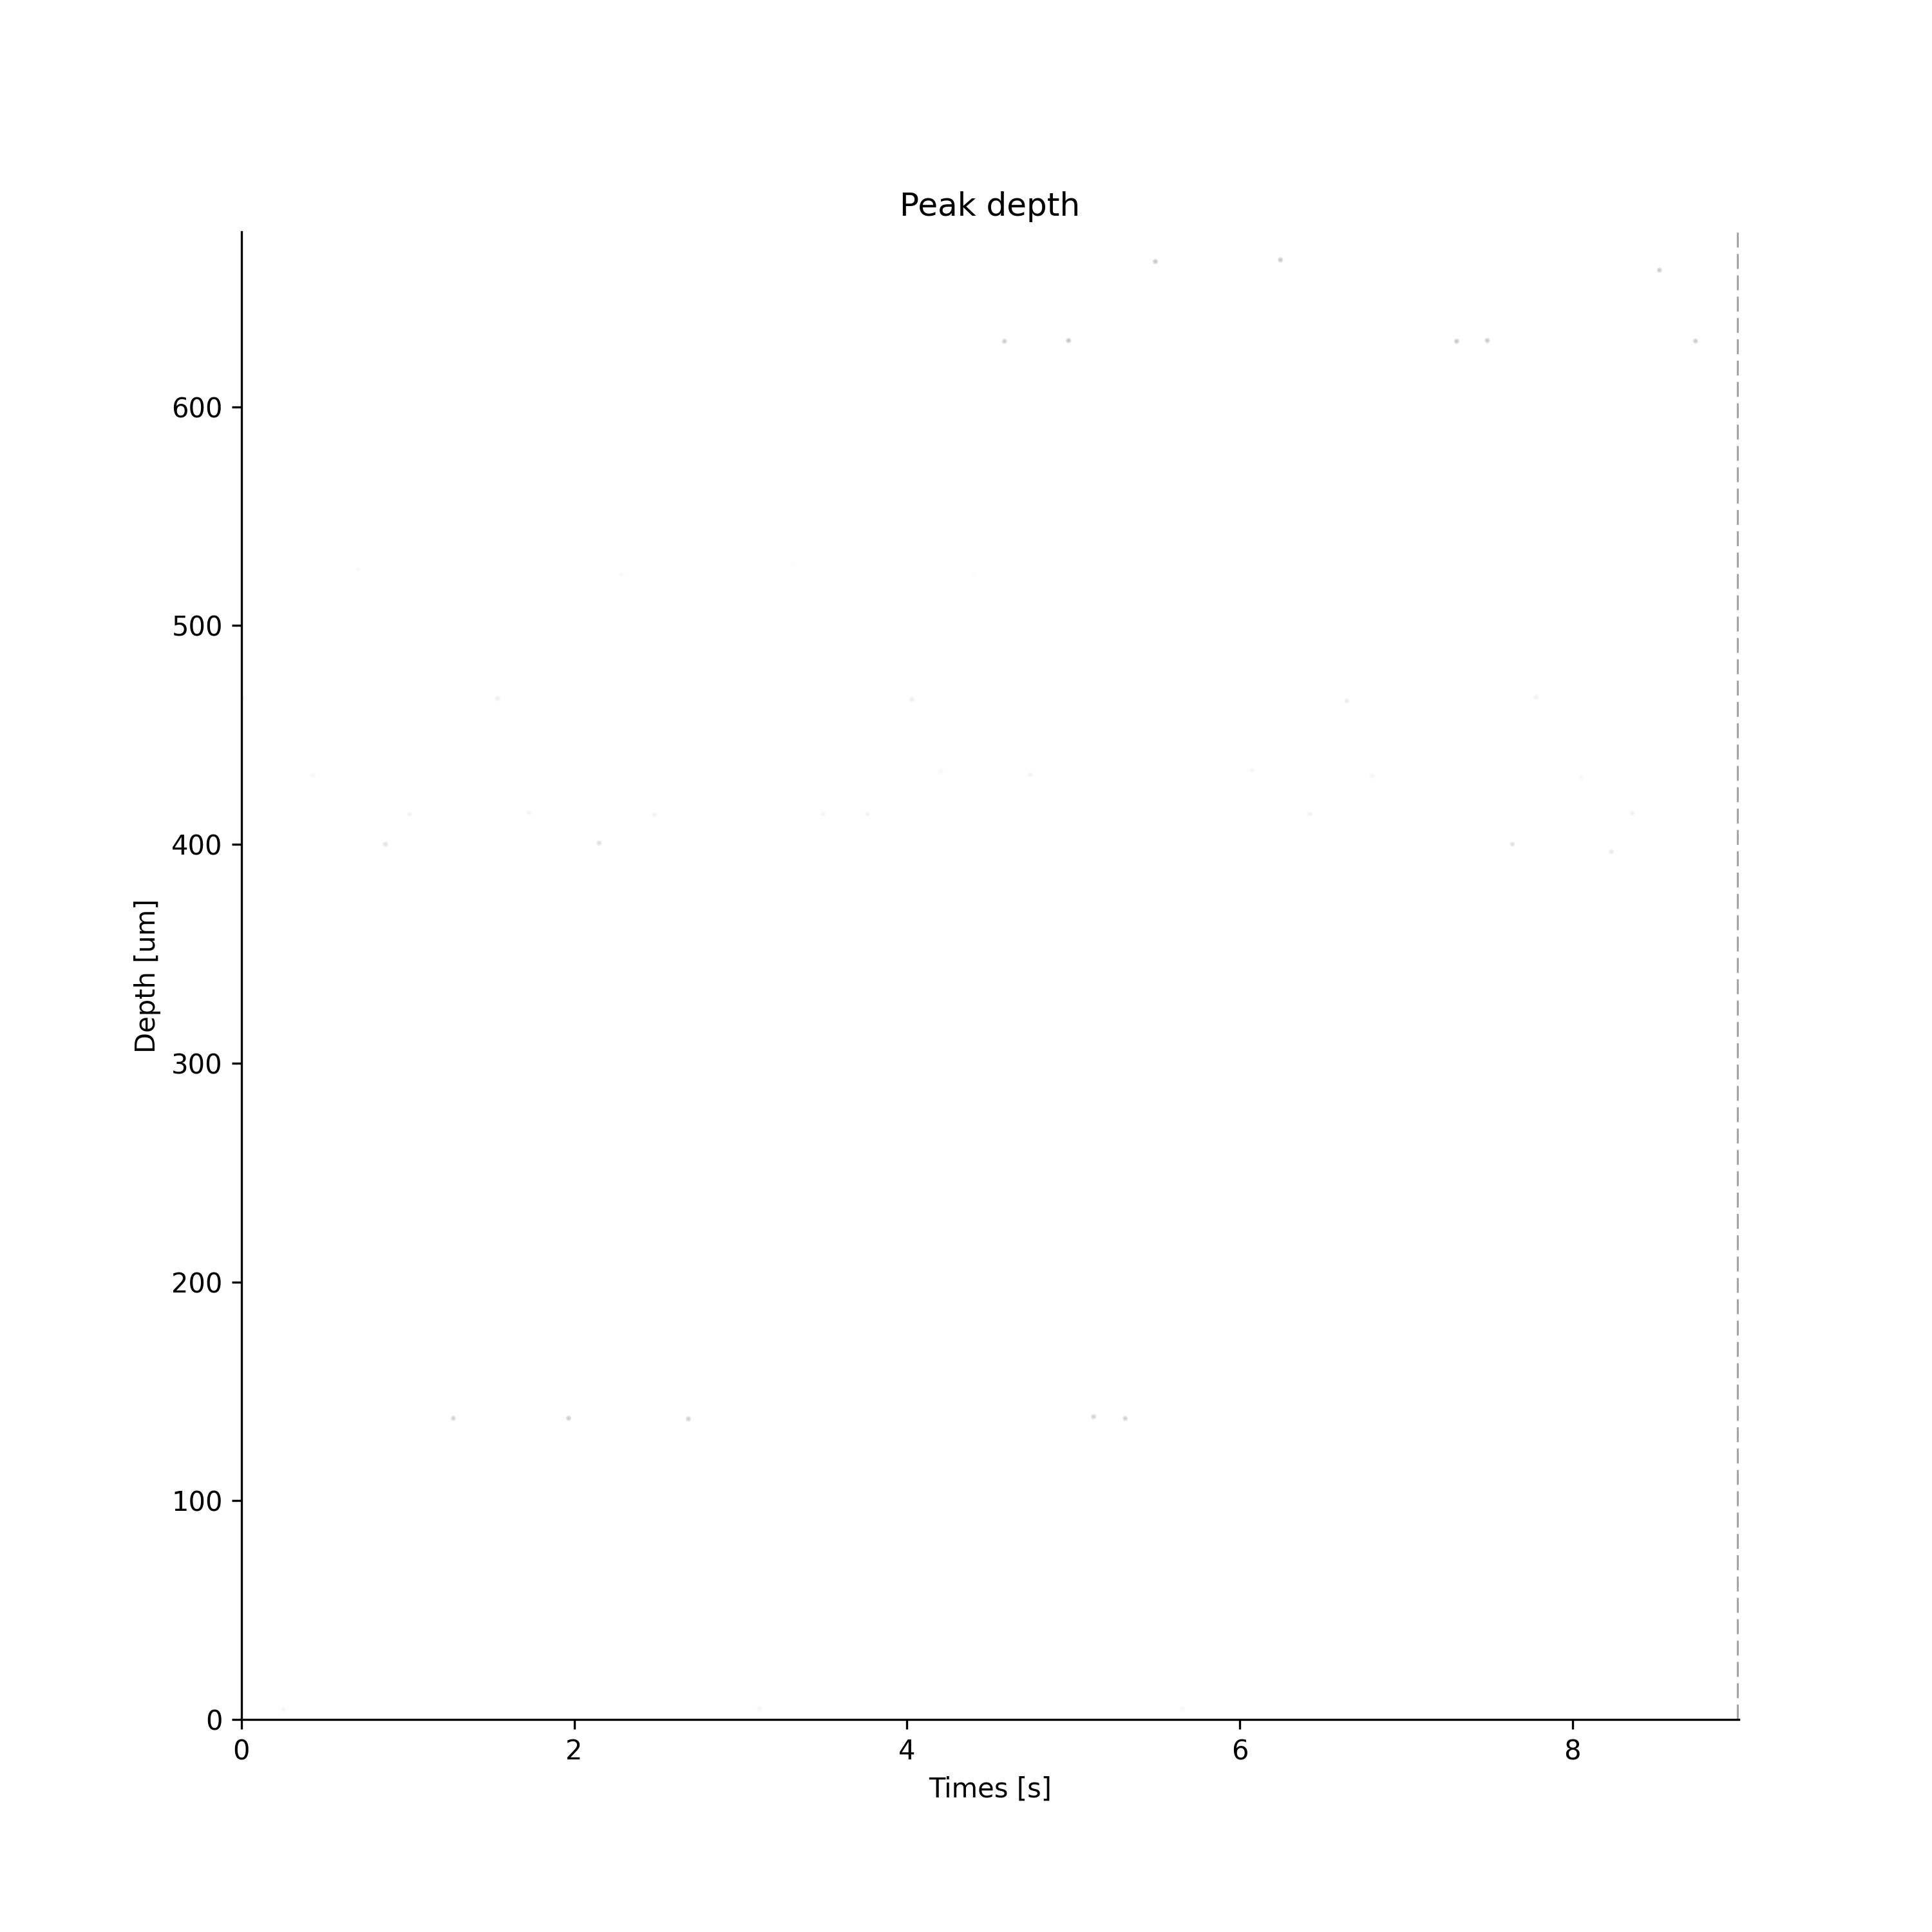

  visualization_block0_None_recording1/traces_full_seg0.png


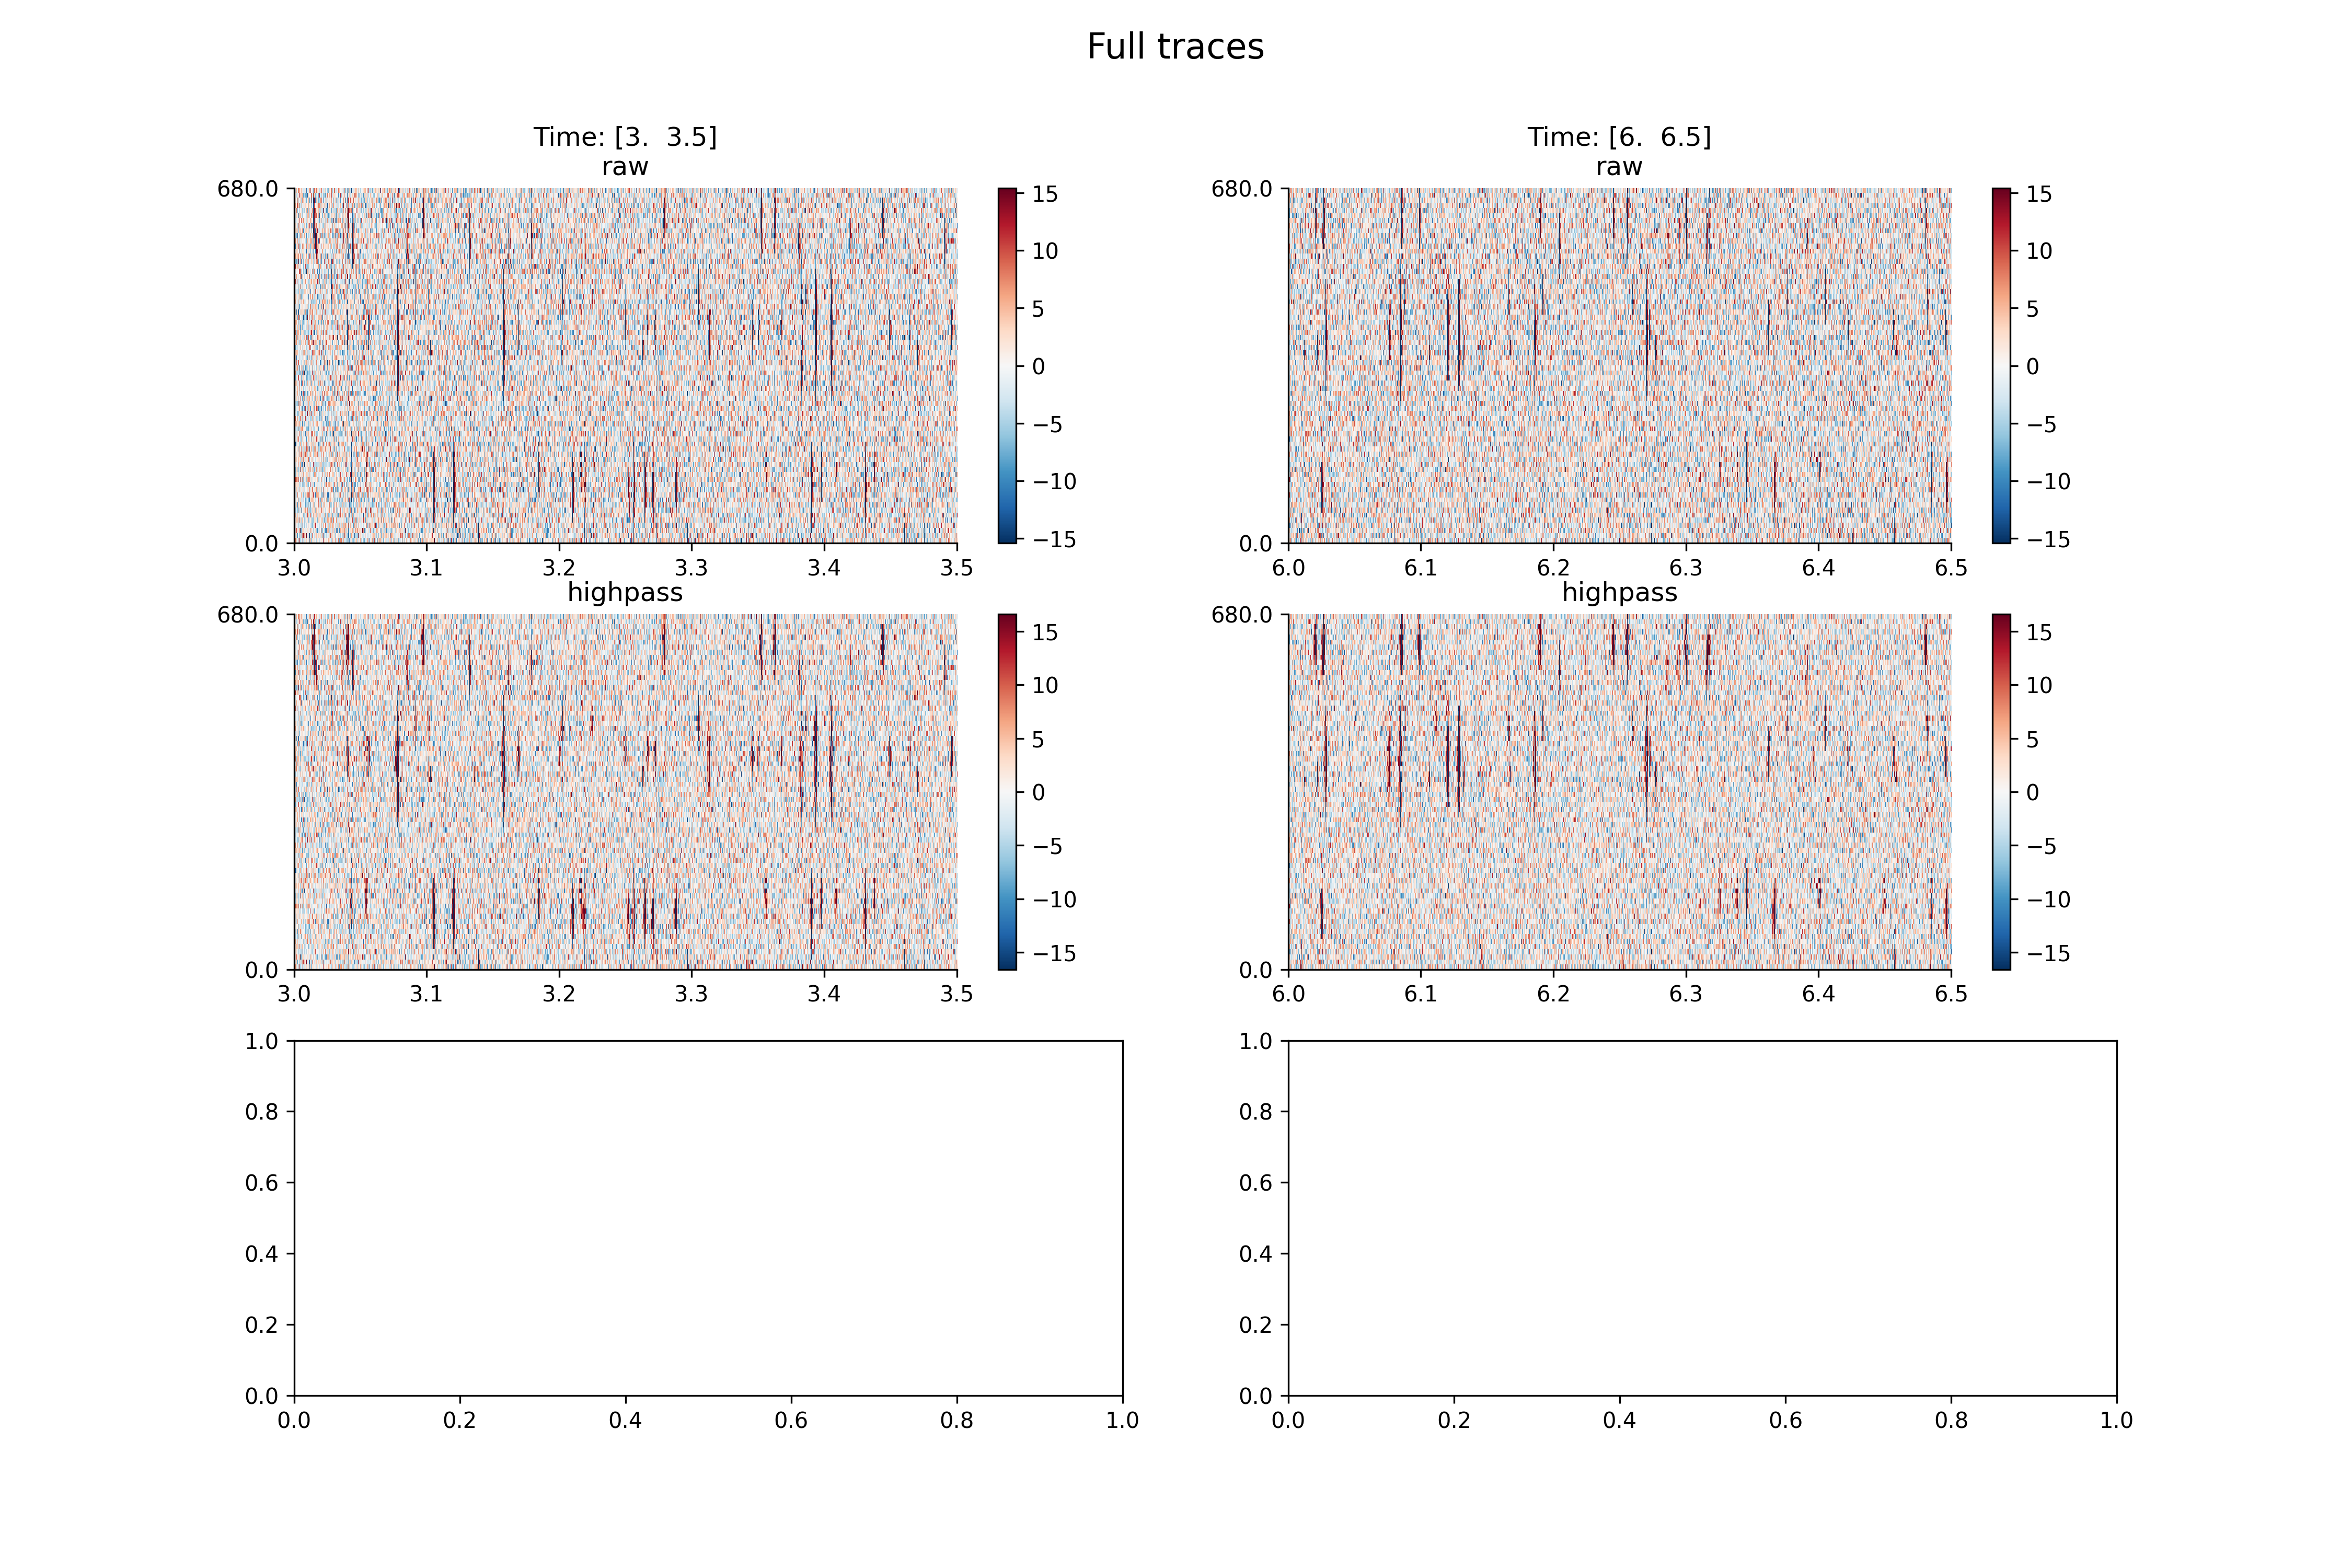

  visualization_block0_None_recording1/traces_proc_seg0.png


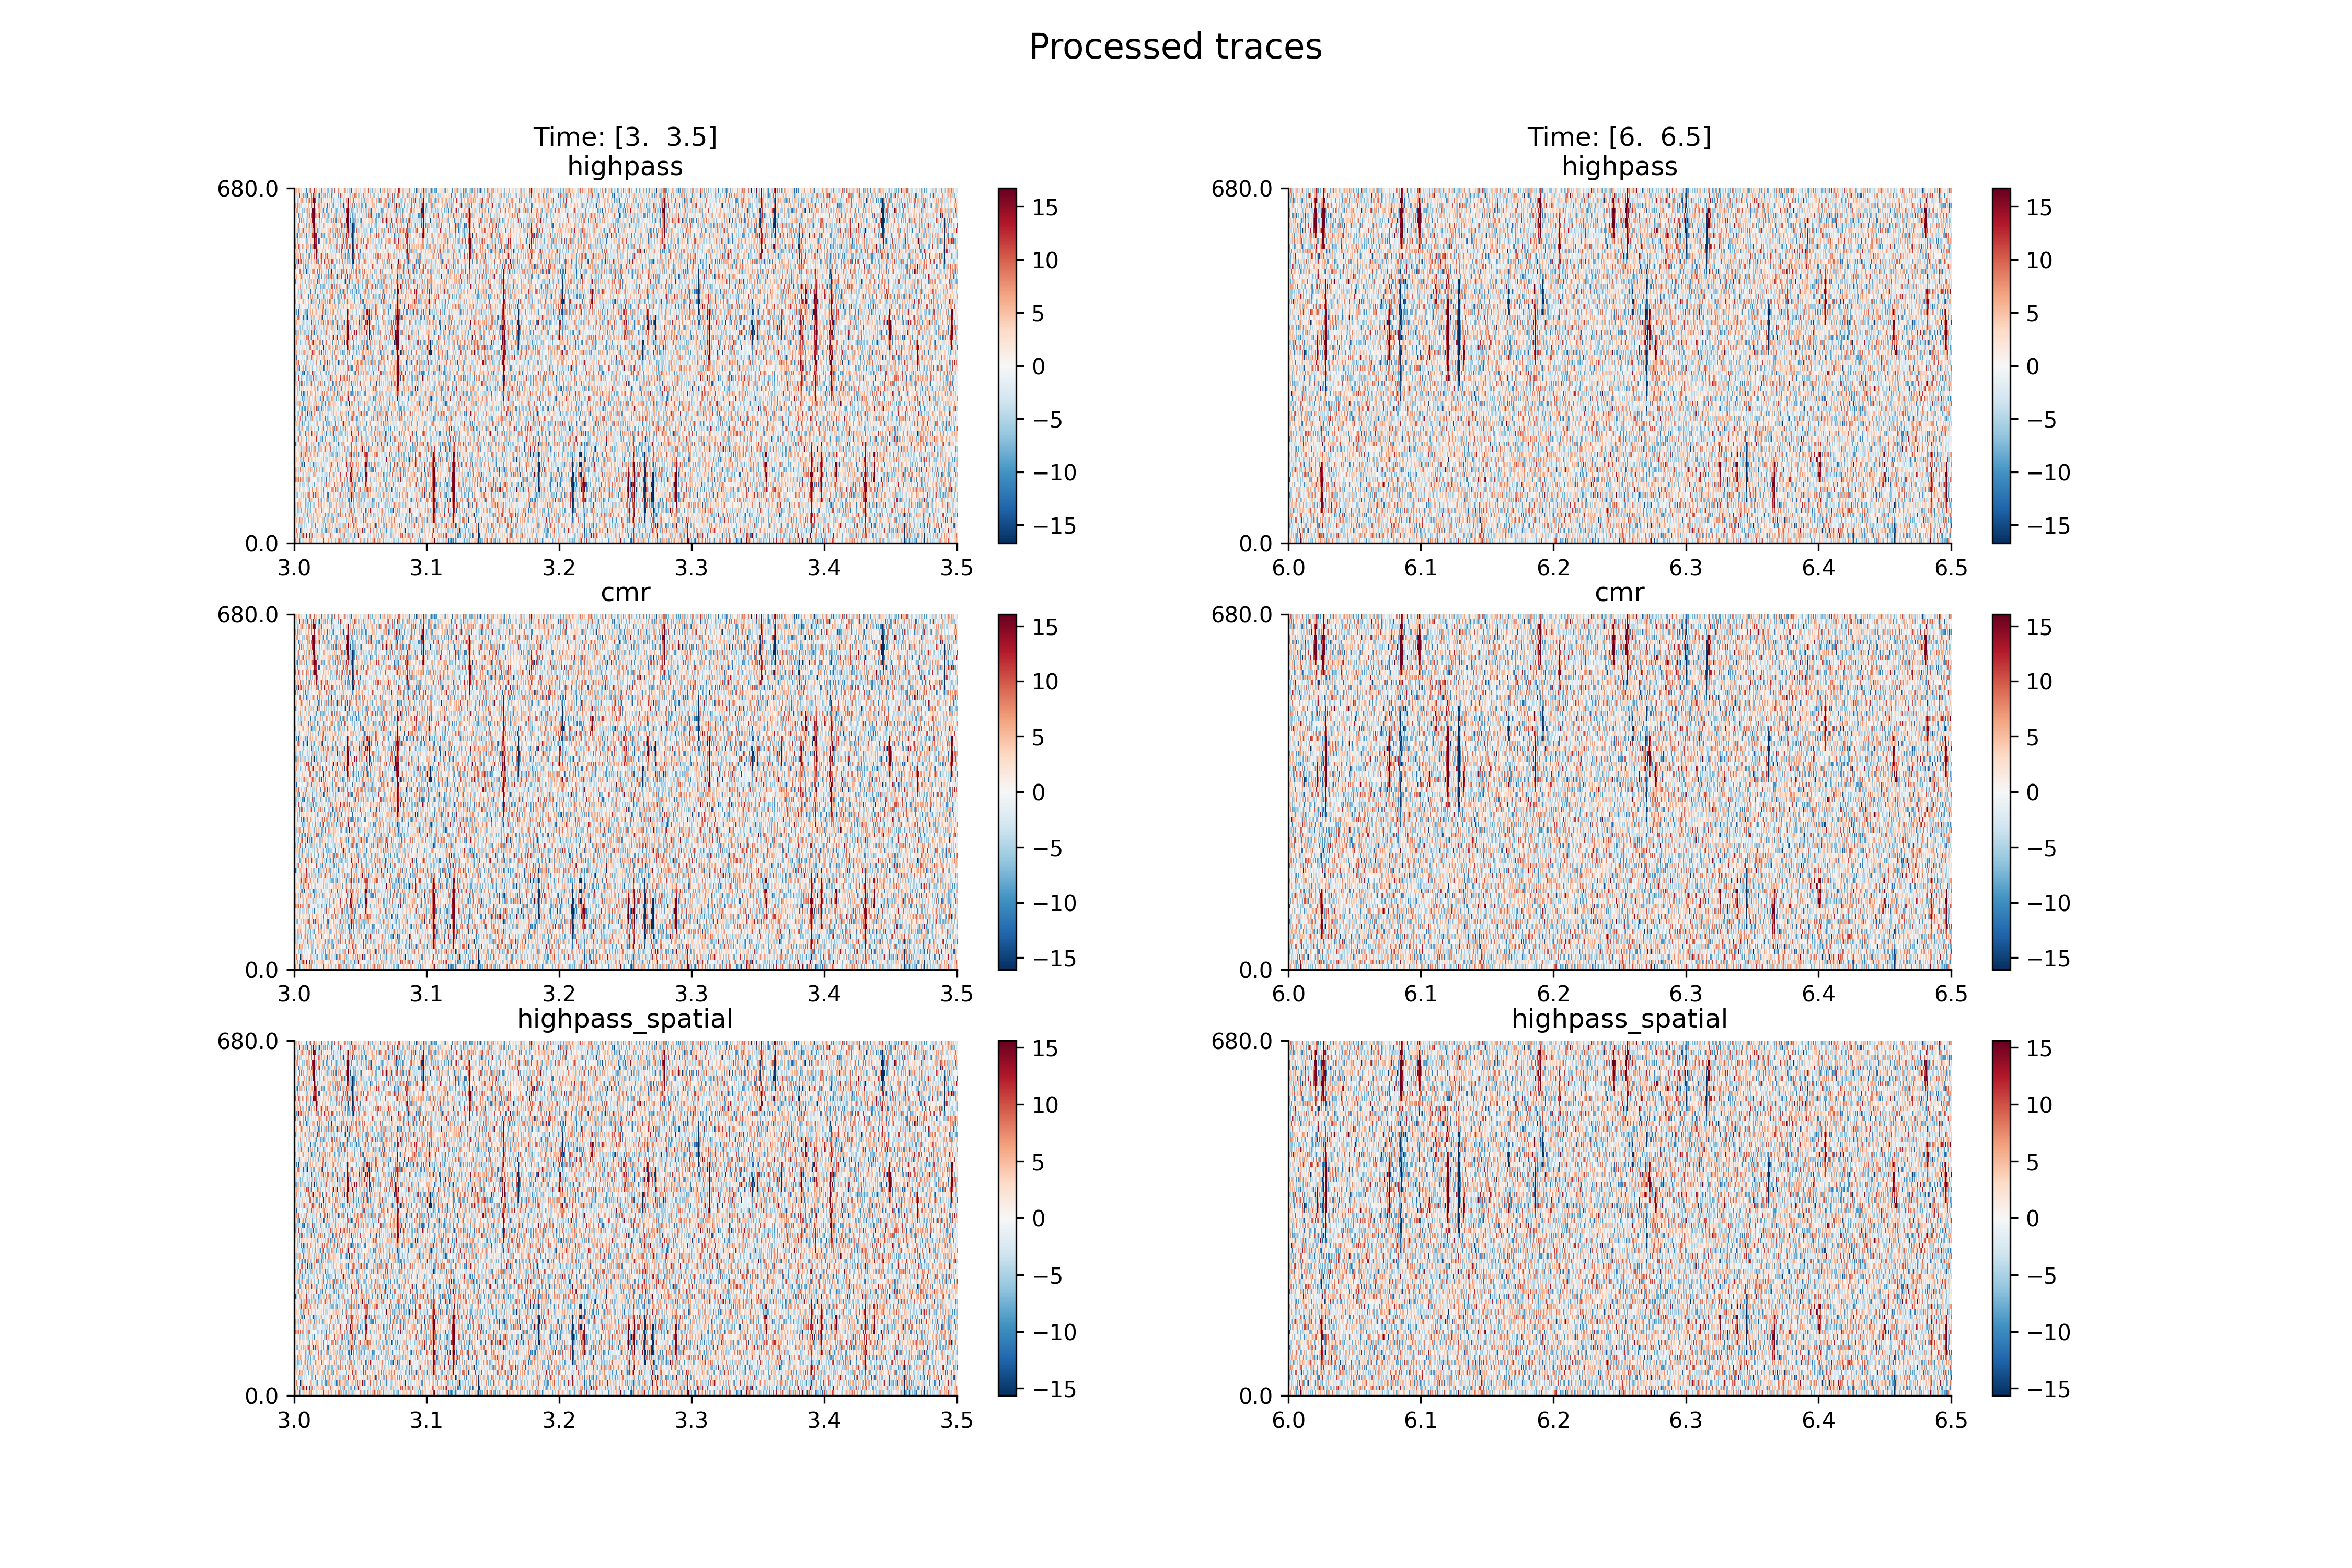

In [5]:
from IPython.display import Image, display

coord_dir = Path(grid_scan.single_configs[0].coordinate_output_root)
print("coordinate_output_root:", coord_dir)

pngs = sorted(coord_dir.rglob("*.png"))
print(f"Generated {len(pngs)} PNG figure(s):")
for p in pngs:
    print(" ", p.relative_to(coord_dir))
    display(Image(filename=str(p)))